In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

In [2]:
# 1. Load the dataset
df = pd.read_csv(filepath_or_buffer='Attitude_Dataset_ML.csv')

In [3]:
# 2. Consolidate Classes
# Mapping 9 specific attitudes to 2 broad categories
mapping = {
    'Growth Mindset': 'Positive',
    'Proactive': 'Positive',
    'Resilient': 'Positive',
    'Collaborative': 'Positive',
    'Empathetic': 'Positive',
    'Accountable': 'Positive',
    'Transparent': 'Positive',
    'Defensive': 'Negative',
    'Complacent': 'Negative'
}
df['Broad_Attitude'] = df['Attitude_Type'].map(mapping)

In [4]:
df['Broad_Attitude'].unique()

array(['Positive', 'Negative'], dtype=object)

In [5]:
df['Broad_Attitude'].value_counts()

Broad_Attitude
Positive    140
Negative     40
Name: count, dtype: int64

In [6]:
df['Broad_Attitude'].value_counts(normalize=True)

Broad_Attitude
Positive    0.777778
Negative    0.222222
Name: proportion, dtype: float64

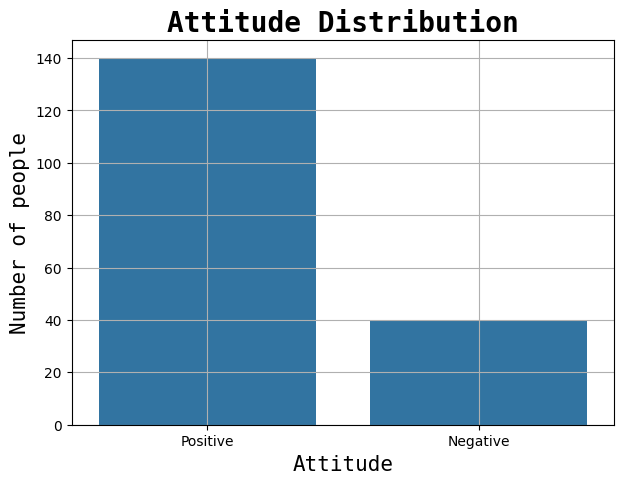

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Creating a barplot for 'Broad Attitude'
ba = df['Broad_Attitude'].value_counts()

plt.style.use('default')
plt.figure(figsize=(7, 5))
sns.barplot(x=ba.index, y=ba.values)
plt.title('Attitude Distribution', fontdict={
          'fontname': 'Monospace', 'fontsize': 20, 'fontweight': 'bold'})
plt.xlabel('Attitude', fontdict={'fontname': 'Monospace', 'fontsize': 15})
plt.ylabel('Number of people', fontdict={
           'fontname': 'Monospace', 'fontsize': 15})
plt.tick_params(labelsize=10)
plt.grid()
plt.show()

In [8]:




# 2. Consolidate Classes
# Mapping 9 specific attitudes to 2 broad categories
mapping = {
    'Growth Mindset': 'Positive',
    'Proactive': 'Positive',
    'Resilient': 'Positive',
    'Collaborative': 'Positive',
    'Empathetic': 'Positive',
    'Accountable': 'Positive',
    'Transparent': 'Positive',
    'Defensive': 'Negative',
    'Complacent': 'Negative'
}
df['Broad_Attitude'] = df['Attitude_Type'].map(mapping)

# 3. Preprocessing
df['combined_text'] = df['Short_Term_Outcome'] + " " + \
                      df['Long_Term_Outcome'] + " " + \
                      df['Recommendation']

X = df['combined_text']
y = df['Broad_Attitude'] # Using the new broad categories

# 4. Vectorization
vectorizer = TfidfVectorizer(ngram_range=(1, 2))
X_vectorized = vectorizer.fit_transform(X)

# 5. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X_vectorized, y, test_size=0.3, random_state=42, stratify=y
)

# 6. Train SVM Classifier with class weights
svm_model = SVC(kernel='linear', C=1.0, class_weight='balanced') # <--- Added class_weight
svm_model.fit(X_train, y_train)
# 7. Evaluation
y_pred = svm_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Improved Accuracy (Broad Classes): {accuracy:.2%}")
# Add zero_division=0 to suppress the warning
print(classification_report(y_test, y_pred, zero_division=0))

Improved Accuracy (Broad Classes): 77.78%
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00        12
    Positive       0.78      1.00      0.88        42

    accuracy                           0.78        54
   macro avg       0.39      0.50      0.44        54
weighted avg       0.60      0.78      0.68        54



In [9]:
def analyze_new_scenario(short_term, long_term):
    """Predicts attitude for a new scenario and returns advice."""
    input_text = short_term + " " + long_term
    input_vec = vectorizer.transform([input_text])
    
    # Predict
    predicted_attitude = svm_model.predict(input_vec)[0]
    
    # --- FIXED PART ---
    # Filter by the new 'Broad_Attitude' column instead of 'Attitude_Type'
    recommendation = df[df['Broad_Attitude'] == predicted_attitude]['Recommendation'].iloc[0]
    
    return predicted_attitude, recommendation

In [10]:
# --- 8. Example Usage ---
example_st = "Missed deadline because I was helping a colleague"
example_lt = "Received positive peer feedback but missed my own targets"

attitude, advice = analyze_new_scenario(example_st, example_lt)

print(f"\n--- Analysis ---")
print(f"Input: {example_st}. {example_lt}")
print(f"Predicted Attitude: {attitude}")
print(f"Advice: {advice}")


--- Analysis ---
Input: Missed deadline because I was helping a colleague. Received positive peer feedback but missed my own targets
Predicted Attitude: Positive
Advice: Continue challenging yourself with advanced technical skills


In [11]:
# --- 8. Example Usage ---
example_st = "Ignored constructive feedback during performance review"
example_lt = "Remained in the same role for 3 years while peers advanced"

attitude, advice = analyze_new_scenario(example_st, example_lt)

print(f"\n--- Analysis ---")
print(f"Input: {example_st}. {example_lt}")
print(f"Predicted Attitude: {attitude}")
print(f"Advice: {advice}")


--- Analysis ---
Input: Ignored constructive feedback during performance review. Remained in the same role for 3 years while peers advanced
Predicted Attitude: Negative
Advice: Take ownership of failures not blame others
